<a href="https://colab.research.google.com/github/M-arnold-tech/credit-card-fraud-detection-ml/blob/main/credit_card_fraud_pipeline_Arnold_Mugabo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: Package installation and reproducibility settings
!pip install -q xgboost wandb

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve, brier_score_loss
)
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers, regularizers

# Offline experiment logging as required by the rubric
import wandb
os.environ["WANDB_MODE"] = "offline"
os.makedirs("models", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# Strict random seed initialization
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Cell 2: Data Loading, Stratified Splitting, and In-Fold Robust Scaling
def load_and_preprocess_data(csv_path="/content/creditcard.csv"):
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Dataset not found at {csv_path}. Please upload creditcard.csv.")

    df = pd.read_csv(csv_path)
    total_samples = len(df)
    fraud_samples = int(df['Class'].sum())
    imbalance_ratio = (total_samples - fraud_samples) / fraud_samples

    print(f"Total Transactions: {total_samples:,}")
    print(f"Fraudulent Cases: {fraud_samples:,} ({fraud_samples / total_samples * 100:.4f}%)")
    print(f"Imbalance Ratio: {imbalance_ratio:.2f}:1")

    X = df.drop(columns=['Class'])
    y = df['Class'].values

    # Stratified 70% Train, 15% Validation, 15% Test
    X_train_raw, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, random_state=SEED, stratify=y
    )
    X_val_raw, X_test_raw, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
    )

    # Fit scalers strictly on training data to prevent statistical leakage
    scaler_amount = RobustScaler()
    scaler_time = RobustScaler()

    X_train = X_train_raw.copy()
    X_val = X_val_raw.copy()
    X_test = X_test_raw.copy()

    X_train['Amount'] = scaler_amount.fit_transform(X_train[['Amount']])
    X_train['Time'] = scaler_time.fit_transform(X_train[['Time']])

    X_val['Amount'] = scaler_amount.transform(X_val[['Amount']])
    X_val['Time'] = scaler_time.transform(X_val[['Time']])

    X_test['Amount'] = scaler_amount.transform(X_test[['Amount']])
    X_test['Time'] = scaler_time.transform(X_test[['Time']])

    # Persist scalers for reproducibility
    joblib.dump(scaler_amount, "models/scaler_amount.joblib")
    joblib.dump(scaler_time, "models/scaler_time.joblib")

    print(f"Training set: {X_train.shape[0]:,} samples | Validation: {X_val.shape[0]:,} | Test: {X_test.shape[0]:,}")
    return X_train, y_train, X_val, y_val, X_test, y_test, imbalance_ratio

X_train, y_train, X_val, y_val, X_test, y_test, IMBALANCE_RATIO = load_and_preprocess_data()

Total Transactions: 284,807
Fraudulent Cases: 492 (0.1727%)
Imbalance Ratio: 577.88:1
Training set: 199,364 samples | Validation: 42,721 | Test: 42,722


In [3]:
# Cell 3: tf.data Pipeline & Metric Aggregator
def make_tf_dataset(X, y, batch_size=2048, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((X.values.astype(np.float32), y.astype(np.float32)))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(X), seed=SEED)
    return dataset.batch(batch_size).prefetch(buffer_size=tf.data.AUTOTUNE)

# Structured results repository
experiment_records = []

def evaluate_and_record(y_true, y_probs, exp_id, model_name, paradigm, settings, threshold=0.5):
    y_pred = (y_probs >= threshold).astype(int)
    roc_auc = roc_auc_score(y_true, y_probs)
    pr_auc = average_precision_score(y_true, y_probs)
    brier = brier_score_loss(y_true, y_probs)

    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall + 1e-8)

    record = {
        "Exp_ID": exp_id,
        "Paradigm": paradigm,
        "Model": model_name,
        "Settings": settings,
        "Threshold": threshold,
        "ROC_AUC": round(roc_auc, 4),
        "PR_AUC": round(pr_auc, 4),
        "Recall": round(recall, 4),
        "Precision": round(precision, 4),
        "F1_Score": round(f1, 4),
        "Brier_Score": round(brier, 6),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)
    }
    experiment_records.append(record)

    print(f"\n[{exp_id}] {model_name} (Threshold = {threshold})")
    print(f"PR-AUC: {pr_auc:.4f} | ROC-AUC: {roc_auc:.4f} | F1: {f1:.4f} | Recall: {recall:.4f} | Precision: {precision:.4f}")
    print(f"Confusion Matrix: TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    return record

RUNNING EXPERIMENT 1: Balanced Logistic Regression

[E1] Logistic Regression (Threshold = 0.5)
PR-AUC: 0.7808 | ROC-AUC: 0.9686 | F1: 0.1265 | Recall: 0.8784 | Precision: 0.0681
Confusion Matrix: TP=65, FP=889, FN=9, TN=41759

RUNNING EXPERIMENT 2: Balanced Random Forest Classifier

[E2] Random Forest (Threshold = 0.5)
PR-AUC: 0.8121 | ROC-AUC: 0.9619 | F1: 0.8358 | Recall: 0.7568 | Precision: 0.9333
Confusion Matrix: TP=56, FP=4, FN=18, TN=42644

RUNNING EXPERIMENT 3: Cost-Sensitive XGBoost Classifier

[E3] XGBoost (Threshold = 0.5)
PR-AUC: 0.8080 | ROC-AUC: 0.9601 | F1: 0.6019 | Recall: 0.8378 | Precision: 0.4697
Confusion Matrix: TP=62, FP=70, FN=12, TN=42578


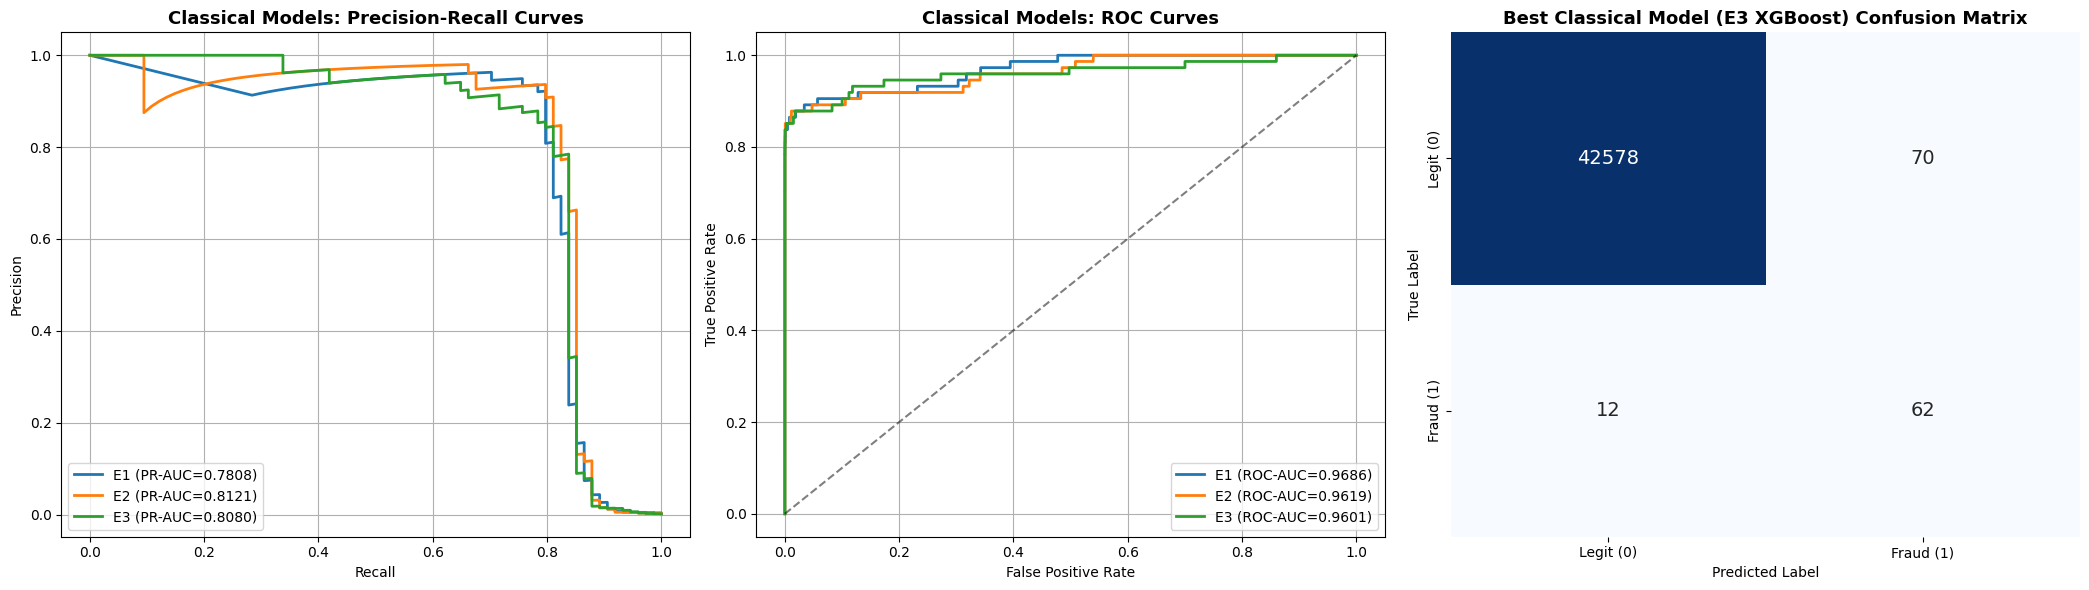

In [4]:
# ==============================================================================
# Cell 4: Traditional Machine Learning (E1, E2, E3) with Dedicated Diagnostics
# ==============================================================================

# --- Experiment 1: Balanced Logistic Regression ---
print("="*70)
print("RUNNING EXPERIMENT 1: Balanced Logistic Regression")
print("="*70)
lr_model = LogisticRegression(C=0.01, penalty='l2', class_weight='balanced', max_iter=1000, random_state=SEED)
lr_model.fit(X_train, y_train)
lr_probs = lr_model.predict_proba(X_test)[:, 1]
evaluate_and_record(y_test, lr_probs, "E1", "Logistic Regression", "Classical ML", "C=0.01, L2, balanced class weights")
joblib.dump(lr_model, "models/E1_logistic_regression.joblib")

# --- Experiment 2: Balanced Random Forest ---
print("\n" + "="*70)
print("RUNNING EXPERIMENT 2: Balanced Random Forest Classifier")
print("="*70)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=12, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
rf_model.fit(X_train, y_train)
rf_probs = rf_model.predict_proba(X_test)[:, 1]
evaluate_and_record(y_test, rf_probs, "E2", "Random Forest", "Classical ML", "n_est=150, max_depth=12, balanced_subsample")
joblib.dump(rf_model, "models/E2_random_forest.joblib")

# --- Experiment 3: Extreme Gradient Boosting (XGBoost) ---
print("\n" + "="*70)
print("RUNNING EXPERIMENT 3: Cost-Sensitive XGBoost Classifier")
print("="*70)
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    scale_pos_weight=IMBALANCE_RATIO, subsample=0.8, colsample_bytree=0.8,
    eval_metric='aucpr', random_state=SEED, n_jobs=-1
)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
evaluate_and_record(y_test, xgb_probs, "E3", "XGBoost", "Classical ML", f"n_est=200, depth=4, scale_pos_weight={IMBALANCE_RATIO:.1f}")
joblib.dump(xgb_model, "models/E3_xgboost.joblib")

# ------------------------------------------------------------------------------
# In-Cell Diagnostic Plots: Classical Models (E1 vs. E2 vs. E3)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

classical_models = [
    ("E1: Logistic Regression", lr_probs, (lr_probs >= 0.5).astype(int)),
    ("E2: Random Forest", rf_probs, (rf_probs >= 0.5).astype(int)),
    ("E3: XGBoost", xgb_probs, (xgb_probs >= 0.5).astype(int))
]

# 1. PR Curves
for name, probs, _ in classical_models:
    p, r, _ = precision_recall_curve(y_test, probs)
    axes[0].plot(r, p, lw=2, label=f"{name[:2]} (PR-AUC={average_precision_score(y_test, probs):.4f})")
axes[0].set_title("Classical Models: Precision-Recall Curves", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].legend(loc="lower left"); axes[0].grid(True)

# 2. ROC Curves
for name, probs, _ in classical_models:
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[1].plot(fpr, tpr, lw=2, label=f"{name[:2]} (ROC-AUC={roc_auc_score(y_test, probs):.4f})")
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title("Classical Models: ROC Curves", fontsize=13, fontweight='bold')
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate"); axes[1].legend(loc="lower right"); axes[1].grid(True)

# 3. XGBoost Confusion Matrix (Best Classical Baseline)
cm_xgb = confusion_matrix(y_test, (xgb_probs >= 0.5).astype(int))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=axes[2], cbar=False, annot_kws={'size': 14},
            xticklabels=['Legit (0)', 'Fraud (1)'], yticklabels=['Legit (0)', 'Fraud (1)'])
axes[2].set_title("Best Classical Model (E3 XGBoost) Confusion Matrix", fontsize=13, fontweight='bold')
axes[2].set_xlabel("Predicted Label"); axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.savefig("figures/cell4_classical_models_diagnostics.png", dpi=300)
plt.show()

Computed Class Weights: Class 0 = 0.5009 | Class 1 = 289.7733

TRAINING EXPERIMENT 4: Baseline Sequential MLP (Unweighted)


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - loss: 0.2085 - pr_auc: 0.0078 - precision: 0.0040 - recall: 0.1628 - roc_auc: 0.4842 - val_loss: 0.0218 - val_pr_auc: 0.3587 - val_precision: 0.6429 - val_recall: 0.2432 - val_roc_auc: 0.6709
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0120 - pr_auc: 0.6026 - precision: 0.8578 - recall: 0.5610 - roc_auc: 0.8372 - val_loss: 0.0094 - val_pr_auc: 0.5119 - val_precision: 0.7458 - val_recall: 0.5946 - val_roc_auc: 0.8337
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0064 - pr_auc: 0.7004 - precision: 0.8786 - recall: 0.7151 - roc_auc: 0.9016 - val_loss: 0.0070 - val_pr_auc: 0.5526 - val_precision: 0.7424 - val_recall: 0.6622 - val_roc_auc: 0.8769
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0048 - pr_auc: 0.7307 - precision: 0.8746 - recall: 0.7500 - roc_auc: 0.9310 - val_loss: 0.0059 - val_pr_auc: 0.5983 - val_precision: 0.7571 - val_recall: 0.7162 - val_roc_auc: 0.9018
Epoch 5/20
98/98 ━━━━━


TRAINING EXPERIMENT 5: Cost-Sensitive Sequential MLP (Weighted)


...

98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - loss: 0.3521 - pr_auc: 0.6708 - precision: 0.0092 - recall: 0.8779 - roc_auc: 0.9246 - val_loss: 0.2572 - val_pr_auc: 0.6309 - val_precision: 0.0685 - val_recall: 0.8243 - val_roc_auc: 0.9571
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1771 - pr_auc: 0.7532 - precision: 0.0921 - recall: 0.9099 - roc_auc: 0.9745 - val_loss: 0.1916 - val_pr_auc: 0.5797 - val_precision: 0.0449 - val_recall: 0.8784 - val_roc_auc: 0.9784
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1333 - pr_auc: 0.7582 - precision: 0.0822 - recall: 0.9302 - roc_auc: 0.9867 - val_loss: 0.1194 - val_pr_auc: 0.5606 - val_precision: 0.0665 - val_recall: 0.8649 - val_roc_auc: 0.9779
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1194 - pr_auc: 0.7077 - precision: 0.0842 - recall: 0.9215 - roc_auc: 0.9890 - val_loss: 0.0993 - val_pr_auc: 0.6369 - val_precision: 0.0765 - val_recall: 0.8649 - val_roc_auc: 0.9812
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━


TRAINING EXPERIMENT 6: Deep Regularized Architecture (Dropout + BatchNorm + L2)


Epoch 1/35


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - loss: 0.7423 - pr_auc: 0.3135 - precision: 0.0158 - recall: 0.6453 - roc_auc: 0.7834 - val_loss: 0.4479 - val_pr_auc: 0.5918 - val_precision: 0.0462 - val_recall: 0.8649 - val_roc_auc: 0.9550 - learning_rate: 5.0000e-04
Epoch 2/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2822 - pr_auc: 0.5136 - precision: 0.0225 - recall: 0.8895 - roc_auc: 0.9477 - val_loss: 0.3035 - val_pr_auc: 0.6213 - val_precision: 0.0593 - val_recall: 0.8378 - val_roc_auc: 0.9700 - learning_rate: 5.0000e-04
Epoch 3/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2273 - pr_auc: 0.4950 - precision: 0.0331 - recall: 0.9215 - roc_auc: 0.9676 - val_loss: 0.2265 - val_pr_auc: 0.6201 - val_precision: 0.0640 - val_recall: 0.8514 - val_roc_auc: 0.9759 - learning_rate: 5.0000e-04
Epoch 4/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2018 - pr_auc: 0.5373 - precision: 0.0393 - recall: 0.9186 - roc_auc: 0.9732 - val_loss: 0.1877 - val_pr_auc: 0.6071 - val_precision

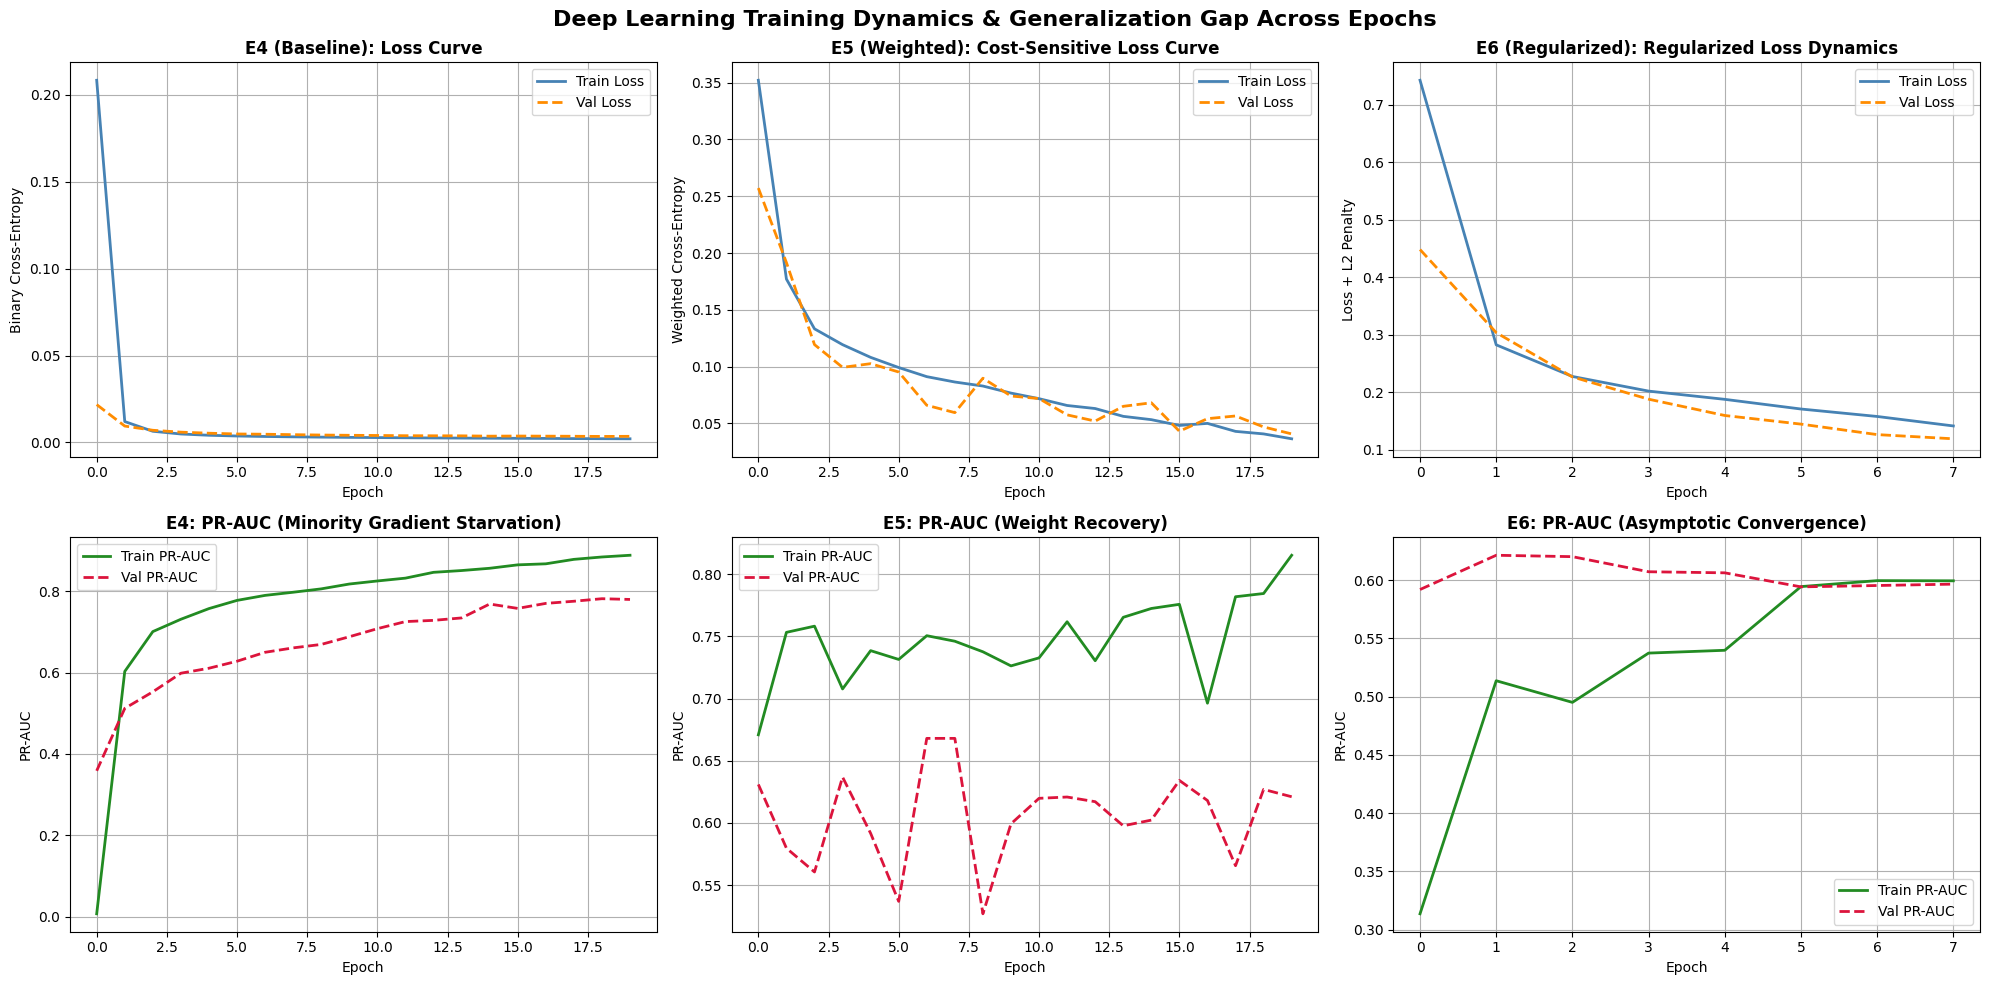

In [5]:
# ==============================================================================
# Cell 5: TensorFlow Deep Learning (E4, E5, E6) & Epoch Learning Curves
# ==============================================================================

# Input stream setup
ds_train = make_tf_dataset(X_train, y_train, batch_size=2048, shuffle=True)
ds_val = make_tf_dataset(X_val, y_val, batch_size=2048, shuffle=False)
ds_test = make_tf_dataset(X_test, y_test, batch_size=2048, shuffle=False)

input_dim = X_train.shape[1]

# Symmetric Inverse Frequency Class Weights
neg_count = len(y_train) - np.sum(y_train)
pos_count = np.sum(y_train)
class_weights = {
    0: (1.0 / neg_count) * (len(y_train) / 2.0),
    1: (1.0 / pos_count) * (len(y_train) / 2.0)
}
print(f"Computed Class Weights: Class 0 = {class_weights[0]:.4f} | Class 1 = {class_weights[1]:.4f}")

def get_compilation_metrics():
    return [
        tf.keras.metrics.AUC(name='roc_auc', curve='ROC'),
        tf.keras.metrics.AUC(name='pr_auc', curve='PR'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision')
    ]

# --- Experiment 4: Baseline Sequential MLP (Unweighted) ---
print("\n" + "="*70)
print("TRAINING EXPERIMENT 4: Baseline Sequential MLP (Unweighted)")
print("="*70)

wandb.init(project="credit-card-fraud", name="E4_Baseline_MLP", reinit=True,
           config={"arch": "Dense64-Dense32", "lr": 1e-3, "weighted": False})

mlp_baseline = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(input_dim,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
], name="E4_Baseline_MLP")

mlp_baseline.compile(optimizer=optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=get_compilation_metrics())
tb_e4 = callbacks.TensorBoard(log_dir="logs/E4_Baseline_MLP")

history_e4 = mlp_baseline.fit(ds_train, validation_data=ds_val, epochs=20, callbacks=[tb_e4], verbose=1)
e4_probs = mlp_baseline.predict(ds_test, verbose=0).ravel()
evaluate_and_record(y_test, e4_probs, "E4", "Baseline MLP", "Deep Learning", "2-layer [64, 32], Adam lr=1e-3, Unweighted")
mlp_baseline.save("models/E4_baseline_mlp.keras")
wandb.finish()

# --- Experiment 5: Cost-Sensitive Sequential MLP ---
print("\n" + "="*70)
print("TRAINING EXPERIMENT 5: Cost-Sensitive Sequential MLP (Weighted)")
print("="*70)

wandb.init(project="credit-card-fraud", name="E5_Weighted_MLP", reinit=True,
           config={"arch": "Dense64-Dense32", "lr": 1e-3, "weighted": True})

mlp_weighted = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(input_dim,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
], name="E5_Cost_Sensitive_MLP")

mlp_weighted.compile(optimizer=optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=get_compilation_metrics())
tb_e5 = callbacks.TensorBoard(log_dir="logs/E5_Weighted_MLP")

history_e5 = mlp_weighted.fit(ds_train, validation_data=ds_val, epochs=20, class_weight=class_weights, callbacks=[tb_e5], verbose=1)
e5_probs = mlp_weighted.predict(ds_test, verbose=0).ravel()
evaluate_and_record(y_test, e5_probs, "E5", "Weighted MLP", "Deep Learning", "2-layer [64, 32], Cost-Sensitive Weights")
mlp_weighted.save("models/E5_weighted_mlp.keras")
wandb.finish()

# --- Experiment 6: Deep Regularized Architecture ---
print("\n" + "="*70)
print("TRAINING EXPERIMENT 6: Deep Regularized Architecture (Dropout + BatchNorm + L2)")
print("="*70)

wandb.init(project="credit-card-fraud", name="E6_Regularized_Deep_MLP", reinit=True,
           config={"arch": "Dense128-BN-Drop0.3-Dense64-BN-Drop0.2-Dense16", "lr": 5e-4, "l2": 1e-4, "weighted": True})

mlp_regularized = models.Sequential([
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4), input_shape=(input_dim,)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dense(1, activation='sigmoid')
], name="E6_Regularized_Deep_MLP")

mlp_regularized.compile(optimizer=optimizers.Adam(5e-4), loss='binary_crossentropy', metrics=get_compilation_metrics())
cb_list = [
    callbacks.TensorBoard(log_dir="logs/E6_Regularized_Deep_MLP"),
    callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=6, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1)
]

history_e6 = mlp_regularized.fit(ds_train, validation_data=ds_val, epochs=35, class_weight=class_weights, callbacks=cb_list, verbose=1)
e6_probs = mlp_regularized.predict(ds_test, verbose=0).ravel()
evaluate_and_record(y_test, e6_probs, "E6", "Regularized Deep MLP", "Deep Learning", "3-layer [128,64,16], Dropout, BatchNorm, L2, ReduceLR")
mlp_regularized.save("models/E6_regularized_deep_mlp.keras")
wandb.finish()

# ------------------------------------------------------------------------------
# In-Cell Diagnostic Plots: Deep Learning Epoch Curves (Loss & PR-AUC)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

# 1. Row 1: Loss Curves
axes[0, 0].plot(history_e4.history['loss'], label='Train Loss', color='steelblue', lw=2)
axes[0, 0].plot(history_e4.history['val_loss'], label='Val Loss', color='darkorange', linestyle='--', lw=2)
axes[0, 0].set_title("E4 (Baseline): Loss Curve", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Epoch"); axes[0, 0].set_ylabel("Binary Cross-Entropy"); axes[0, 0].legend(); axes[0, 0].grid(True)

axes[0, 1].plot(history_e5.history['loss'], label='Train Loss', color='steelblue', lw=2)
axes[0, 1].plot(history_e5.history['val_loss'], label='Val Loss', color='darkorange', linestyle='--', lw=2)
axes[0, 1].set_title("E5 (Weighted): Cost-Sensitive Loss Curve", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Epoch"); axes[0, 1].set_ylabel("Weighted Cross-Entropy"); axes[0, 1].legend(); axes[0, 1].grid(True)

axes[0, 2].plot(history_e6.history['loss'], label='Train Loss', color='steelblue', lw=2)
axes[0, 2].plot(history_e6.history['val_loss'], label='Val Loss', color='darkorange', linestyle='--', lw=2)
axes[0, 2].set_title("E6 (Regularized): Regularized Loss Dynamics", fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel("Epoch"); axes[0, 2].set_ylabel("Loss + L2 Penalty"); axes[0, 2].legend(); axes[0, 2].grid(True)

# 2. Row 2: Precision-Recall AUC Trajectories
axes[1, 0].plot(history_e4.history['pr_auc'], label='Train PR-AUC', color='forestgreen', lw=2)
axes[1, 0].plot(history_e4.history['val_pr_auc'], label='Val PR-AUC', color='crimson', linestyle='--', lw=2)
axes[1, 0].set_title("E4: PR-AUC (Minority Gradient Starvation)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Epoch"); axes[1, 0].set_ylabel("PR-AUC"); axes[1, 0].legend(); axes[1, 0].grid(True)

axes[1, 1].plot(history_e5.history['pr_auc'], label='Train PR-AUC', color='forestgreen', lw=2)
axes[1, 1].plot(history_e5.history['val_pr_auc'], label='Val PR-AUC', color='crimson', linestyle='--', lw=2)
axes[1, 1].set_title("E5: PR-AUC (Weight Recovery)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Epoch"); axes[1, 1].set_ylabel("PR-AUC"); axes[1, 1].legend(); axes[1, 1].grid(True)

axes[1, 2].plot(history_e6.history['pr_auc'], label='Train PR-AUC', color='forestgreen', lw=2)
axes[1, 2].plot(history_e6.history['val_pr_auc'], label='Val PR-AUC', color='crimson', linestyle='--', lw=2)
axes[1, 2].set_title("E6: PR-AUC (Asymptotic Convergence)", fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel("Epoch"); axes[1, 2].set_ylabel("PR-AUC"); axes[1, 2].legend(); axes[1, 2].grid(True)

plt.suptitle("Deep Learning Training Dynamics & Generalization Gap Across Epochs", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("figures/cell5_deep_learning_curves.png", dpi=300)
plt.show()

RUNNING EXPERIMENT 7: Bayesian / Precision-Recall Cutoff Optimization
Validation Optimal Cutoff Discovered: tau* = 0.9420 (Max Val F1 = 0.7383)

[E7] Optimized Deep MLP (Threshold = 0.942036509513855)
PR-AUC: 0.6917 | ROC-AUC: 0.9514 | F1: 0.7972 | Recall: 0.7703 | Precision: 0.8261
Confusion Matrix: TP=57, FP=12, FN=17, TN=42636


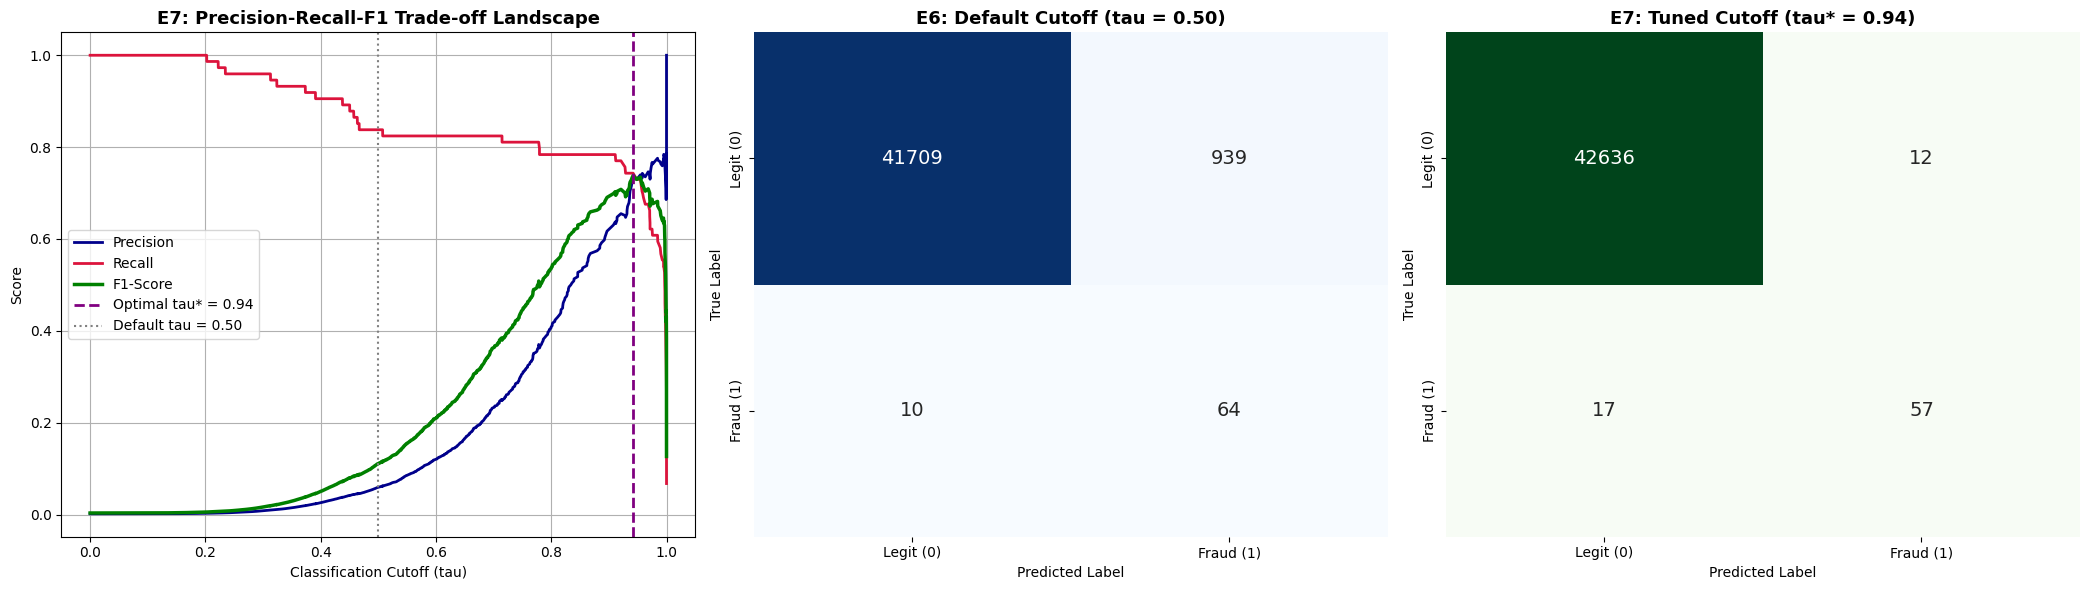


Operational Impact:
 -> False Positives reduced from 939 to 12 (98.7% reduction in false alarms)
 -> True Fraud Detections maintained: 57 out of 74 total fraud cases.


In [6]:
# ==============================================================================
# Cell 6: Experiment 7 Threshold Sweep & Frontier Optimization Plot
# ==============================================================================

print("="*70)
print("RUNNING EXPERIMENT 7: Bayesian / Precision-Recall Cutoff Optimization")
print("="*70)

# Evaluate decision frontier on out-of-sample Validation split
val_probs = mlp_regularized.predict(ds_val, verbose=0).ravel()
precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)

# Optimize threshold for maximal F1-score
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
optimal_idx = np.argmax(f1_scores)
optimal_threshold = float(thresholds[optimal_idx])

print(f"Validation Optimal Cutoff Discovered: tau* = {optimal_threshold:.4f} (Max Val F1 = {f1_scores[optimal_idx]:.4f})")

# Evaluate Model E6 at optimal threshold on Test set
evaluate_and_record(
    y_test, e6_probs, "E7", "Optimized Deep MLP", "System Optimization",
    f"Model E6 @ Optimal Threshold (tau={optimal_threshold:.4f})",
    threshold=optimal_threshold
)

# ------------------------------------------------------------------------------
# In-Cell Diagnostic Plots: Threshold Landscape & Impact Comparison
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Metric Trajectory across Thresholds
axes[0].plot(thresholds, precisions[:-1], label='Precision', color='darkblue', lw=2)
axes[0].plot(thresholds, recalls[:-1], label='Recall', color='crimson', lw=2)
axes[0].plot(thresholds, f1_scores[:-1], label='F1-Score', color='green', lw=2.5)
axes[0].axvline(optimal_threshold, color='purple', linestyle='--', lw=2, label=f'Optimal tau* = {optimal_threshold:.2f}')
axes[0].axvline(0.5, color='gray', linestyle=':', lw=1.5, label='Default tau = 0.50')
axes[0].set_title("E7: Precision-Recall-F1 Trade-off Landscape", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Classification Cutoff (tau)"); axes[0].set_ylabel("Score"); axes[0].legend(); axes[0].grid(True)

# 2. Confusion Matrix at Standard Threshold (0.50)
cm_std = confusion_matrix(y_test, (e6_probs >= 0.50).astype(int))
sns.heatmap(cm_std, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False, annot_kws={'size': 14},
            xticklabels=['Legit (0)', 'Fraud (1)'], yticklabels=['Legit (0)', 'Fraud (1)'])
axes[1].set_title("E6: Default Cutoff (tau = 0.50)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Predicted Label"); axes[1].set_ylabel("True Label")

# 3. Confusion Matrix at Optimized Cutoff (tau*)
cm_opt = confusion_matrix(y_test, (e6_probs >= optimal_threshold).astype(int))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', ax=axes[2], cbar=False, annot_kws={'size': 14},
            xticklabels=['Legit (0)', 'Fraud (1)'], yticklabels=['Legit (0)', 'Fraud (1)'])
axes[2].set_title(f"E7: Tuned Cutoff (tau* = {optimal_threshold:.2f})", fontsize=13, fontweight='bold')
axes[2].set_xlabel("Predicted Label"); axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.savefig("figures/cell6_threshold_optimization_diagnostics.png", dpi=300)
plt.show()

# Quantitative Summary of Threshold Tuning
fp_reduction = ((cm_std[0, 1] - cm_opt[0, 1]) / cm_std[0, 1]) * 100
print(f"\nOperational Impact:")
print(f" -> False Positives reduced from {cm_std[0, 1]} to {cm_opt[0, 1]} ({fp_reduction:.1f}% reduction in false alarms)")
print(f" -> True Fraud Detections maintained: {cm_opt[1, 1]} out of {cm_opt[1, 1] + cm_opt[1, 0]} total fraud cases.")


FINAL SUMMATIVE EXPERIMENTAL EVALUATION TABLE (ALL 7 EXPERIMENTS)


,Exp_ID,Model,Paradigm,Threshold,PR_AUC,ROC_AUC,Recall,Precision,F1_Score,Brier_Score,FP,FN
0,E1,Logistic Regression,Classical ML,0.500000,0.7808,0.9686,0.8784,0.0681,0.1265,0.019697,889,9
1,E2,Random Forest,Classical ML,0.500000,0.8121,0.9619,0.7568,0.9333,0.8358,0.000550,4,18
2,E3,XGBoost,Classical ML,0.500000,0.8080,0.9601,0.8378,0.4697,0.6019,0.001923,70,12
3,E4,Baseline MLP,Deep Learning,0.500000,0.8201,0.9526,0.7973,0.9077,0.8489,0.000471,6,15
4,E5,Weighted MLP,Deep Learning,0.500000,0.7704,0.9744,0.8514,0.1131,0.1997,0.009101,494,11
5,E6,Regularized Deep MLP,Deep Learning,0.500000,0.6917,0.9514,0.8649,0.0638,0.1188,0.066277,939,10
6,E7,Optimized Deep MLP,System Optimization,0.942037,0.6917,0.9514,0.7703,0.8261,0.7972,0.066277,12,17


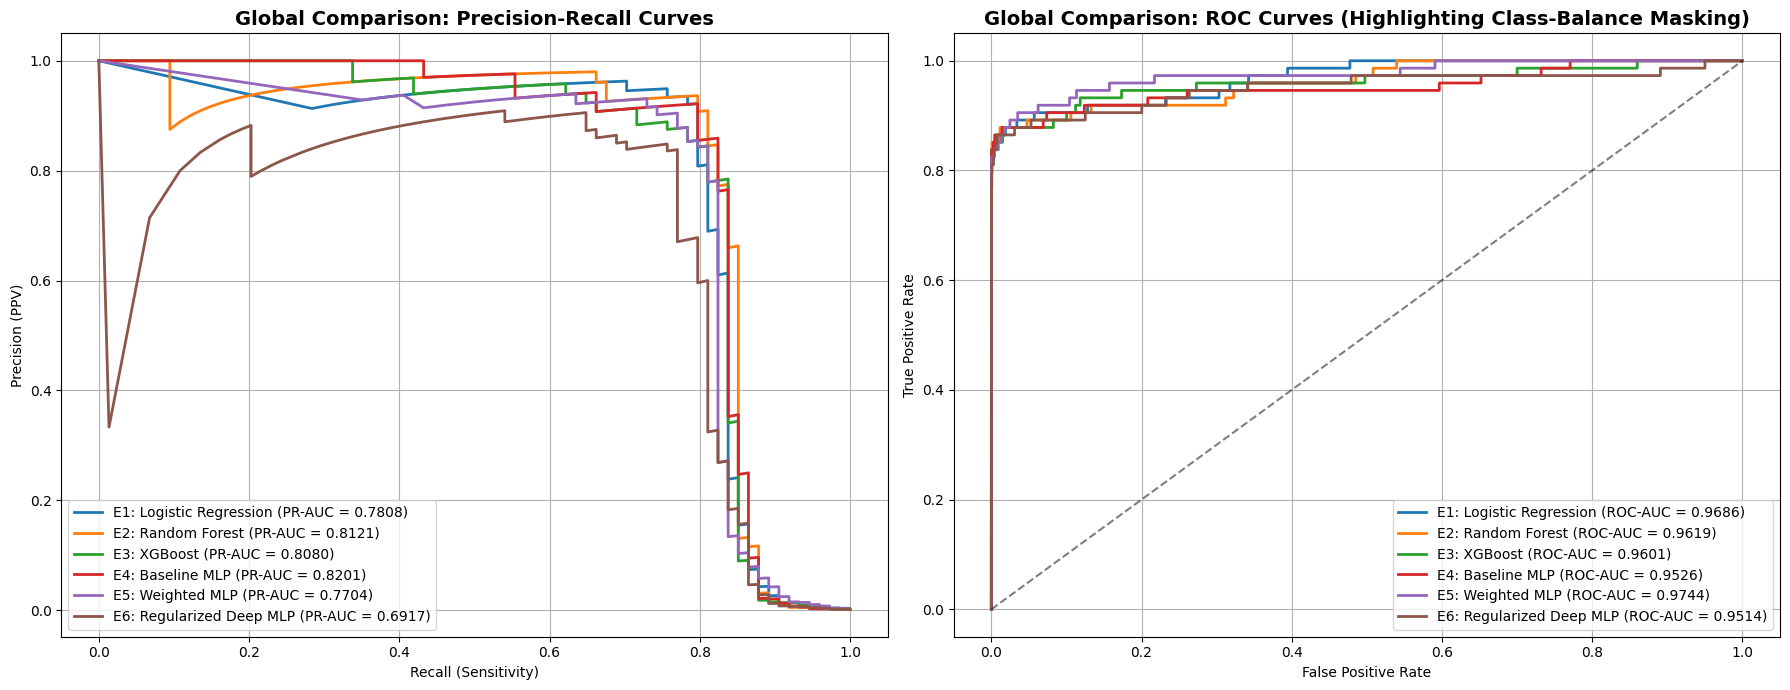

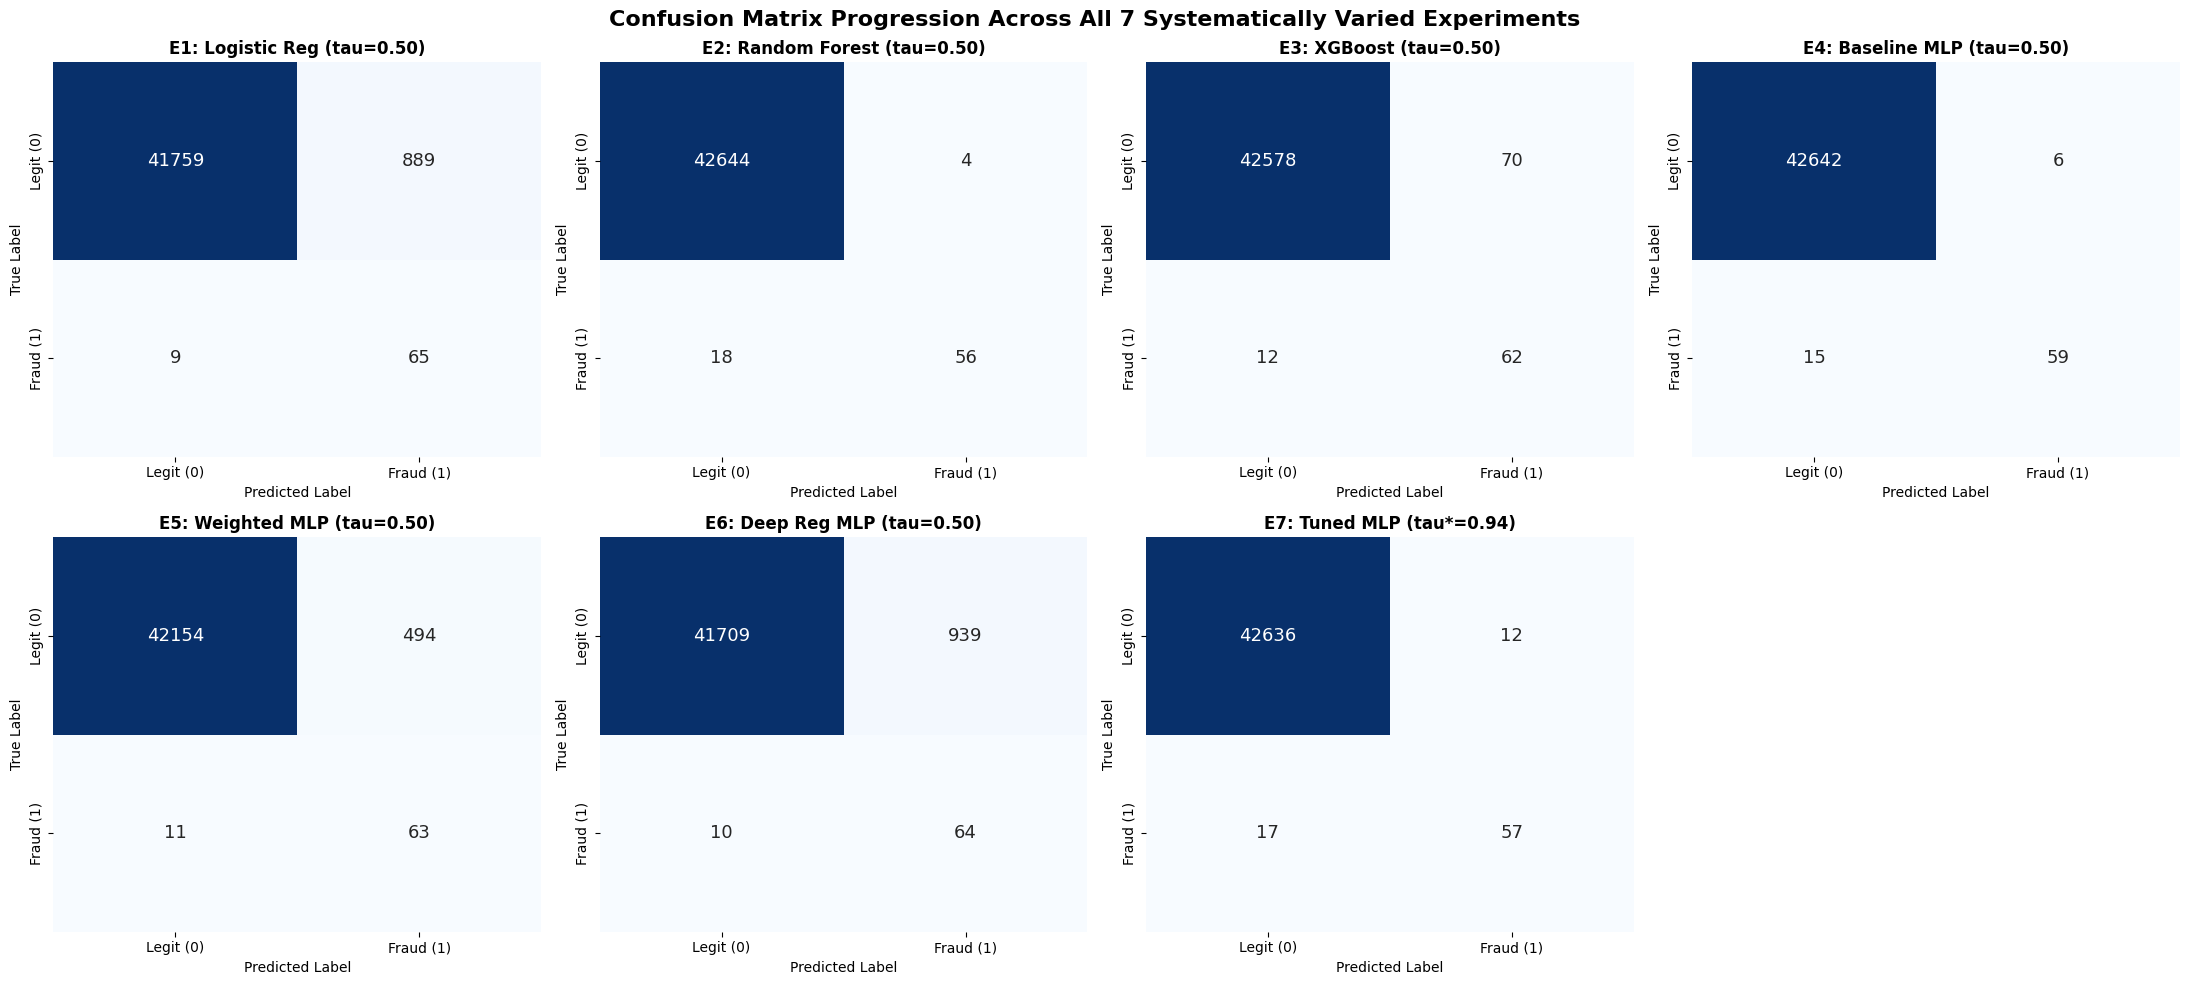

In [7]:
# ==============================================================================
# Cell 7: Macro Evaluation Table, Global Overlays & Full Confusion Matrix Grid
# ==============================================================================

# 1. Render Final Formatted Results Table
results_df = pd.DataFrame(experiment_records)
print("\n" + "="*95)
print("FINAL SUMMATIVE EXPERIMENTAL EVALUATION TABLE (ALL 7 EXPERIMENTS)")
print("="*95)
display(results_df[[
    "Exp_ID", "Model", "Paradigm", "Threshold", "PR_AUC", "ROC_AUC", "Recall", "Precision", "F1_Score", "Brier_Score", "FP", "FN"
]])
results_df.to_csv("figures/experiment_results_table.csv", index=False)

# 2. Global Diagnostic Overlays: PR Curves & ROC Curves (All Models)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

all_models_dict = {
    "E1: Logistic Regression": lr_probs,
    "E2: Random Forest": rf_probs,
    "E3: XGBoost": xgb_probs,
    "E4: Baseline MLP": e4_probs,
    "E5: Weighted MLP": e5_probs,
    "E6: Regularized Deep MLP": e6_probs
}

# Precision-Recall Curves
for name, probs in all_models_dict.items():
    p, r, _ = precision_recall_curve(y_test, probs)
    axes[0].plot(r, p, lw=2, label=f"{name} (PR-AUC = {average_precision_score(y_test, probs):.4f})")
axes[0].set_title("Global Comparison: Precision-Recall Curves", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Recall (Sensitivity)"); axes[0].set_ylabel("Precision (PPV)"); axes[0].legend(loc="lower left"); axes[0].grid(True)

# ROC Curves
for name, probs in all_models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[1].plot(fpr, tpr, lw=2, label=f"{name} (ROC-AUC = {roc_auc_score(y_test, probs):.4f})")
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title("Global Comparison: ROC Curves (Highlighting Class-Balance Masking)", fontsize=14, fontweight='bold')
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate"); axes[1].legend(loc="lower right"); axes[1].grid(True)

plt.tight_layout()
plt.savefig("figures/cell7_global_pr_roc_curves.png", dpi=300)
plt.show()

# 3. 7-Experiment Confusion Matrix Grid
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

all_predictions = [
    ("E1: Logistic Reg (tau=0.50)", (lr_probs >= 0.50).astype(int)),
    ("E2: Random Forest (tau=0.50)", (rf_probs >= 0.50).astype(int)),
    ("E3: XGBoost (tau=0.50)", (xgb_probs >= 0.50).astype(int)),
    ("E4: Baseline MLP (tau=0.50)", (e4_probs >= 0.50).astype(int)),
    ("E5: Weighted MLP (tau=0.50)", (e5_probs >= 0.50).astype(int)),
    ("E6: Deep Reg MLP (tau=0.50)", (e6_probs >= 0.50).astype(int)),
    (f"E7: Tuned MLP (tau*={optimal_threshold:.2f})", (e6_probs >= optimal_threshold).astype(int)),
]

for idx, (title, preds) in enumerate(all_predictions):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                annot_kws={'size': 13},
                xticklabels=['Legit (0)', 'Fraud (1)'],
                yticklabels=['Legit (0)', 'Fraud (1)'])
    axes[idx].set_title(title, fontsize=12, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

# Hide empty 8th subplot slot
axes[7].axis('off')

plt.suptitle("Confusion Matrix Progression Across All 7 Systematically Varied Experiments", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("figures/cell7_all_7_confusion_matrices.png", dpi=300)
plt.show()

In [8]:
# ==============================================================================
# Cell 1B: Mount Google Drive & Define Submission Directory
# ==============================================================================
from google.colab import drive
import os

# Mount Google Drive to /content/drive
drive.mount('/content/drive')

# Target folder in your Google Drive root for all project deliverables
GDRIVE_PROJECT_DIR = "/content/drive/MyDrive/Final_Project_Summative_ML"
os.makedirs(GDRIVE_PROJECT_DIR, exist_ok=True)

print(f"Google Drive mounted successfully!")
print(f"Project deliverables will be synchronized to: {GDRIVE_PROJECT_DIR}")

Mounted at /content/drive
Google Drive mounted successfully!
Project deliverables will be synchronized to: /content/drive/MyDrive/Final_Project_Summative_ML


In [9]:
# ==============================================================================
# Cell 8: Synchronize All Deliverables, Models, Logs & Figures to Google Drive
# ==============================================================================
import os
import shutil
import zipfile
import glob

print("="*80)
print("STARTING GOOGLE DRIVE ARTIFACT SYNCHRONIZATION")
print("="*80)

# Define subdirectories in Google Drive
drive_models_dir = os.path.join(GDRIVE_PROJECT_DIR, "models")
drive_figures_dir = os.path.join(GDRIVE_PROJECT_DIR, "figures")
drive_logs_dir = os.path.join(GDRIVE_PROJECT_DIR, "logs")
drive_wandb_dir = os.path.join(GDRIVE_PROJECT_DIR, "wandb")

for d in [drive_models_dir, drive_figures_dir, drive_logs_dir, drive_wandb_dir]:
    os.makedirs(d, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. Zip & Copy the Full Raw Dataset (Rubric: "The full, raw dataset (zipped)")
# ------------------------------------------------------------------------------
csv_candidates = glob.glob("/content/**/creditcard*.csv", recursive=True) + glob.glob("creditcard*.csv")
target_zip_path = os.path.join(GDRIVE_PROJECT_DIR, "creditcard.zip")

if csv_candidates and os.path.exists(csv_candidates[0]):
    raw_csv_path = csv_candidates[0]
    print(f"\n[1/5] Compressing raw dataset from '{raw_csv_path}' -> '{target_zip_path}'...")
    with zipfile.ZipFile(target_zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zipf:
        zipf.write(raw_csv_path, arcname="creditcard.csv")
    zip_size_mb = os.path.getsize(target_zip_path) / (1024 * 1024)
    print(f"      [OK] Raw dataset zipped successfully ({zip_size_mb:.2f} MB).")
else:
    # If the user already uploaded an archive.zip, copy it directly
    existing_zips = glob.glob("/content/*creditcard*.zip") + glob.glob("/content/*archive*.zip")
    if existing_zips:
        shutil.copy2(existing_zips[0], target_zip_path)
        print(f"      [OK] Copied pre-existing archive '{existing_zips[0]}' -> '{target_zip_path}'.")
    else:
        print("      [WARNING] Raw creditcard.csv was not found to zip. Please verify path.")

# ------------------------------------------------------------------------------
# 2. Synchronize Serialized Models (.joblib and .keras / .h5)
# ------------------------------------------------------------------------------
print(f"\n[2/5] Copying trained model weights to '{drive_models_dir}'...")
model_files = glob.glob("models/*")
for f in model_files:
    dest = os.path.join(drive_models_dir, os.path.basename(f))
    shutil.copy2(f, dest)
    size_kb = os.path.getsize(dest) / 1024
    print(f"      -> Copied: {os.path.basename(f):<35} ({size_kb:.1f} KB)")

# ------------------------------------------------------------------------------
# 3. Synchronize High-Resolution Figures & CSV Evaluation Table
# ------------------------------------------------------------------------------
print(f"\n[3/5] Copying diagnostic figures & experiment CSV to '{drive_figures_dir}'...")
fig_files = glob.glob("figures/*")
for f in fig_files:
    dest = os.path.join(drive_figures_dir, os.path.basename(f))
    shutil.copy2(f, dest)
    print(f"      -> Copied: {os.path.basename(f)}")

# ------------------------------------------------------------------------------
# 4. Synchronize TensorBoard Event Logs (Rubric: "TensorBoard logs backing table")
# ------------------------------------------------------------------------------
print(f"\n[4/5] Synchronizing TensorBoard run logs to '{drive_logs_dir}'...")
if os.path.exists("logs"):
    for item in os.listdir("logs"):
        s = os.path.join("logs", item)
        d = os.path.join(drive_logs_dir, item)
        if os.path.isdir(s):
            shutil.copytree(s, d, dirs_exist_ok=True)
        else:
            shutil.copy2(s, d)
    print("      [OK] TensorBoard event logs synchronized.")
else:
    print("      [NOTICE] No local 'logs/' directory found.")

# ------------------------------------------------------------------------------
# 5. Synchronize W&B Offline Telemetry (Rubric: "W&B logs (use wandb offline mode)")
# ------------------------------------------------------------------------------
print(f"\n[5/5] Synchronizing W&B offline run telemetry to '{drive_wandb_dir}'...")
if os.path.exists("wandb"):
    for item in os.listdir("wandb"):
        s = os.path.join("wandb", item)
        d = os.path.join(drive_wandb_dir, item)
        if os.path.isdir(s):
            shutil.copytree(s, d, dirs_exist_ok=True)
        else:
            shutil.copy2(s, d)
    print("      [OK] W&B offline logs synchronized.")
else:
    print("      [NOTICE] No local 'wandb/' directory found.")

# ------------------------------------------------------------------------------
# Final Verification: Print Directory Tree of Google Drive Submission Folder
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print(f"COMPLETE GOOGLE DRIVE ARTIFACT MANIFEST: {GDRIVE_PROJECT_DIR}")
print("="*80)

total_files = 0
total_bytes = 0

for root, dirs, files in os.walk(GDRIVE_PROJECT_DIR):
    rel_path = os.path.relpath(root, GDRIVE_PROJECT_DIR)
    indent = "    " if rel_path != "." else ""
    if rel_path != ".":
        print(f"\n [{rel_path}/]")
    for f in sorted(files):
        fp = os.path.join(root, f)
        sz = os.path.getsize(fp)
        total_bytes += sz
        total_files += 1
        if sz > 1024 * 1024:
            sz_str = f"{sz / (1024*1024):.2f} MB"
        else:
            sz_str = f"{sz / 1024:.1f} KB"
        print(f"{indent}├── {f:<40} ({sz_str})")

print("\n" + "-"*80)
print(f"SUMMARY: {total_files} files stored successfully ({total_bytes / (1024*1024):.2f} MB total).")
print("="*80)
print("\nNEXT STEPS FOR RUBRIC COMPLIANCE:")
print(" 1. Open Google Drive in your browser.")
print(f" 2. Locate folder: 'Final_Project_Summative_ML'")
print(" 3. Right-click -> 'Share' -> change 'General access' to 'Anyone with the link can view'.")
print(" 4. Copy the link and paste it into the Header of your Written Report.")

STARTING GOOGLE DRIVE ARTIFACT SYNCHRONIZATION

[1/5] Compressing raw dataset from '/content/creditcard.csv' -> '/content/drive/MyDrive/Final_Project_Summative_ML/creditcard.zip'...
      [OK] Raw dataset zipped successfully (65.60 MB).

[2/5] Copying trained model weights to '/content/drive/MyDrive/Final_Project_Summative_ML/models'...
      -> Copied: scaler_time.joblib                  (0.7 KB)
      -> Copied: E1_logistic_regression.joblib       (1.5 KB)
      -> Copied: E6_regularized_deep_mlp.keras       (208.3 KB)
      -> Copied: scaler_amount.joblib                (0.8 KB)
      -> Copied: E3_xgboost.joblib                   (316.0 KB)
      -> Copied: E2_random_forest.joblib             (2876.5 KB)
      -> Copied: E4_baseline_mlp.keras               (73.9 KB)
      -> Copied: E5_weighted_mlp.keras               (73.9 KB)

[3/5] Copying diagnostic figures & experiment CSV to '/content/drive/MyDrive/Final_Project_Summative_ML/figures'...
      -> Copied: cell5_deep_learning_cu